# Long-term ERA5 wave conditions near Vĩnh Châu

This notebook converts the 2025 ERA5 record into simple, model-ready wave and wind conditions for the Vĩnh Châu–Nhà Mát area.

The workflow is: load the data once, choose the offshore location and analysis settings, inspect the observations, calculate long-term conditions, identify independent threshold peaks, and prepare a Delft3D input summary.

# 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import find_peaks


By default (`SAVE = False`), the notebook only shows the figures and tables, so the files in `results/` are not changed.
Set `SAVE = True` to save them in `results/storm/` -> this overwrites the files there.

In [ ]:
SAVE = False   # True = save the figures and tables in results/storm/ (overwrites the files there)

result_dir = Path('../results/storm')

if SAVE:
    result_dir.mkdir(parents=True, exist_ok=True)

# 2. Load ERA5 data

This cell opens the ERA5 fields once. Do not rerun it when only the analysis settings change.

In [ ]:
era5_path = Path('../data/data_storm/Era5_2025.grib')
if not era5_path.exists():
    raise FileNotFoundError(f'Could not find {era5_path}')


era5_datasets = {}


def open_grib_variable(short_name):
    dataset = xr.open_dataset(
        era5_path,
        engine='cfgrib',
        backend_kwargs={
            'filter_by_keys': {'shortName': short_name},
            'indexpath': ''
        }
    )
    era5_datasets[short_name] = dataset
    return dataset[list(dataset.data_vars)[0]]


# Load the fields once. Later cells reuse these in-memory variables.
hs = open_grib_variable('swh')
tp = open_grib_variable('pp1d')
tm0 = open_grib_variable('mwp')
wave_dir = open_grib_variable('mwd')
u10 = open_grib_variable('10u')
v10 = open_grib_variable('10v')

lat_name = 'latitude' if 'latitude' in hs.coords else 'lat'
lon_name = 'longitude' if 'longitude' in hs.coords else 'lon'


def time_axis(variable):
    for name in ('time', 'valid_time'):
        if name in variable.dims:
            if 'valid_time' in variable.coords and variable.sizes[name] == variable.valid_time.size:
                return pd.to_datetime(variable.valid_time.values)
            return pd.to_datetime(variable[name].values)
    raise ValueError('No time dimension found.')


def point_series(variable):
    values = variable.sel({lat_name: selected_lat, lon_name: selected_lon}, method='nearest')
    return pd.Series(np.asarray(values.values, dtype=float), index=time_axis(values))


def circular_mean(degrees):
    values = pd.Series(degrees).dropna().to_numpy(dtype=float)
    if len(values) == 0:
        return np.nan
    radians = np.deg2rad(values)
    return float(np.rad2deg(np.arctan2(np.mean(np.sin(radians)), np.mean(np.cos(radians)))) % 360)


print(f'Loaded ERA5 fields: {", ".join(era5_datasets)}')

Loaded ERA5 fields: swh, pp1d, mwp, mwd, 10u, 10v


# 3. Input conditions

Edit the location, threshold, peak separation, and season definitions here. The selected ERA5 grid cell is printed below.

In [3]:
# Analysis inputs
location_lat = 8.75
location_lon = 105.95
threshold_m = 1.5
minimum_peak_distance_hours = 120

season_months = {
    'NE Monsoon': (11, 12, 1, 2, 3, 4),
    'SW Monsoon': (6, 7, 8, 9),
    'Transition': (5, 10)
}

selected_lat = float(hs[lat_name].sel({lat_name: location_lat}, method='nearest'))
selected_lon = float(hs[lon_name].sel({lon_name: location_lon}, method='nearest'))

raw_observations = pd.DataFrame({
    'Hs_m': point_series(hs),
    'Tp_s': point_series(tp),
    'Tm0_s': point_series(tm0),
    'Wave_direction_deg': point_series(wave_dir),
    'u10_ms': point_series(u10),
    'v10_ms': point_series(v10)
}).sort_index()
raw_observations['Wind_speed_ms'] = np.hypot(raw_observations['u10_ms'], raw_observations['v10_ms'])
raw_observations = raw_observations.replace([np.inf, -np.inf], np.nan).dropna(subset=['Hs_m'])
observations = raw_observations.copy()

print(f'Requested location: {location_lat:.3f} N, {location_lon:.3f} E')
print(f'Selected ERA5 grid cell: {selected_lat:.3f} N, {selected_lon:.3f} E')
print(f'Threshold: {threshold_m:.1f} m | Peak distance: {minimum_peak_distance_hours:.0f} hours')

Requested location: 8.750 N, 105.950 E
Selected ERA5 grid cell: 9.000 N, 106.000 E
Threshold: 1.5 m | Peak distance: 120 hours


# 4. Apply the moving-average filter

A centred six-hour moving average is applied to every numeric analysis variable. Wave direction is filtered with circular averaging so directions near 0/360 degrees are handled correctly. The filtered table becomes the only input for the inspection, long-term statistics, storm detection, event duration, and Delft3D summary.

In [4]:
time_step_hours = raw_observations.index.to_series().diff().dt.total_seconds().median() / 3600
missing_values = raw_observations.isna().sum()
if missing_values.any():
    print('Missing values are retained; no temporal interpolation is applied because no measured values are available to reconstruct them.')
else:
    print('No missing values were found, so no temporal interpolation is needed.')

moving_average_hours = 6
moving_average_window = max(1, int(np.ceil(moving_average_hours / time_step_hours)))
filtered_observations = raw_observations.drop(columns='Wind_speed_ms').rolling(
    window=moving_average_window,
    center=True,
    min_periods=moving_average_window
).mean()

# Average wave direction circularly rather than averaging degree values directly.
direction_radians = np.deg2rad(raw_observations['Wave_direction_deg'])
filtered_sine = pd.Series(np.sin(direction_radians), index=raw_observations.index).rolling(
    window=moving_average_window,
    center=True,
    min_periods=moving_average_window
).mean()
filtered_cosine = pd.Series(np.cos(direction_radians), index=raw_observations.index).rolling(
    window=moving_average_window,
    center=True,
    min_periods=moving_average_window
).mean()
filtered_observations['Wave_direction_deg'] = np.rad2deg(
    np.arctan2(filtered_sine, filtered_cosine)
) % 360
filtered_observations['Wind_speed_ms'] = np.hypot(
    filtered_observations['u10_ms'],
    filtered_observations['v10_ms']
)

# All downstream analysis uses the filtered values.
observations = filtered_observations.dropna(subset=['Hs_m']).copy()

print(f'Hourly time step: {time_step_hours:.1f} hours')
print(f'Applied centred moving-average window: {moving_average_hours} hours')
print(f'Observations used after filtering: {len(observations):,}')
display(missing_values.to_frame('count').T)

No missing values were found, so no temporal interpolation is needed.
Hourly time step: 1.0 hours
Applied centred moving-average window: 6 hours
Observations used after filtering: 8,755


,Hs_m,Tp_s,Tm0_s,Wave_direction_deg,u10_ms,v10_ms,Wind_speed_ms
count,0,0,0,0,0,0,0


# 5. Inspect observations

This cell checks the record length, sampling interval, selected grid cell, missing values, and basic statistics before the long-term and storm analyses.

In [5]:
time_step_hours = observations.index.to_series().diff().dt.total_seconds().median() / 3600
# print(f'Observations: {len(observations):,}')
# print(f'Period: {observations.index.min()} to {observations.index.max()}')
# print(f'Median time step: {time_step_hours:.1f} hours')
# display(observations.head())
# display(observations.tail())
# display(observations.describe().round(3))

# 6. Long-term hydrodynamic conditions

This cell calculates annual, seasonal, and monthly wave and wind statistics from the six-hour filtered observations. Filtering is used consistently so the long-term conditions and storm conditions describe the same processed dataset.

Long-term wave and wind conditions


,Observations,Mean Hs (m),95th percentile Hs (m),Maximum Hs (m),Mean Tp (s),Mean Tm0 (s),Mean wave direction (deg),Mean u10 (m/s),Mean v10 (m/s),Mean wind speed (m/s)
Period,,,,,,,,,,
Annual,8755,0.722,1.524,2.070,4.985,4.136,135.577,-0.503,0.271,5.884
NE Monsoon,3619,0.904,1.710,2.049,5.691,4.701,81.790,-5.541,-1.122,6.385
SW Monsoon,2928,0.637,0.983,1.191,4.185,3.569,227.722,5.477,2.219,6.277
Transition,2208,0.536,1.284,2.070,4.887,3.963,139.941,-0.177,-0.030,4.542


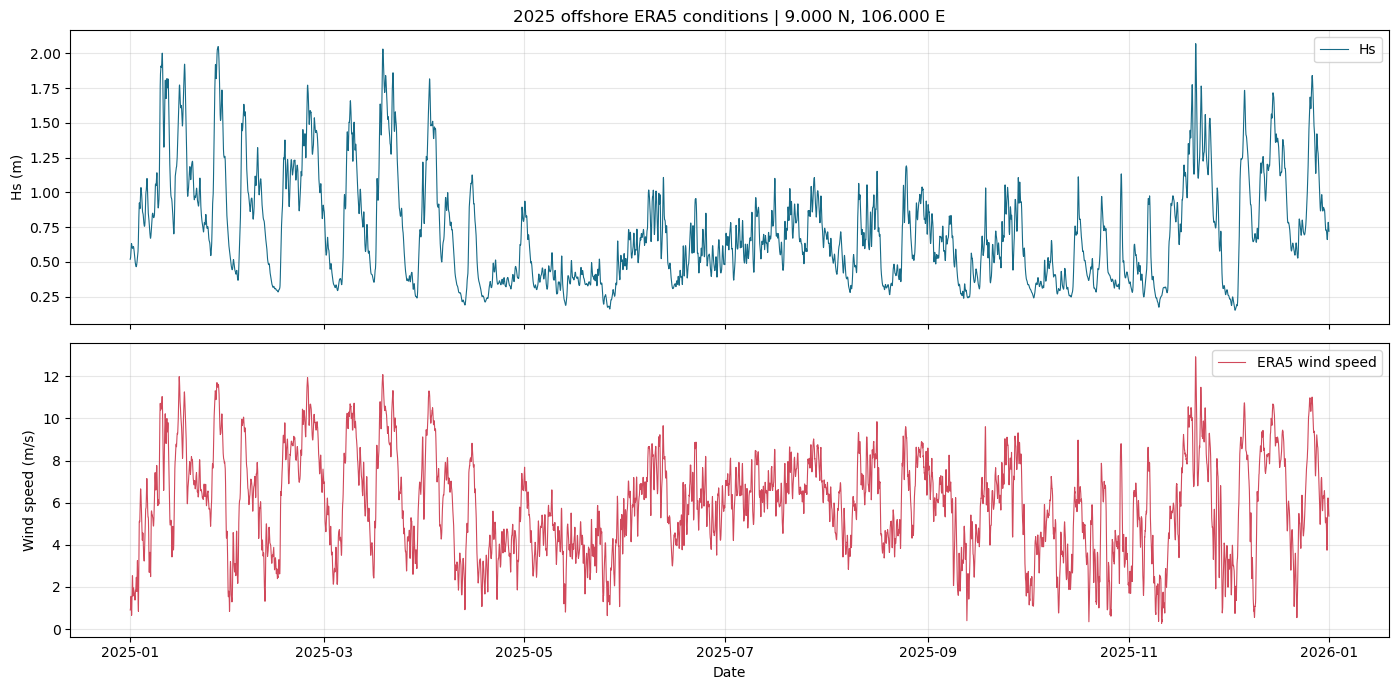

In [ ]:
def season_for_month(month):
    for season, months in season_months.items():
        if month in months:
            return season
    raise ValueError(f'Month {month} is not assigned to a season.')


seasonal_observations = observations.copy()
seasonal_observations['Season'] = [season_for_month(month) for month in seasonal_observations.index.month]

summary_rows = []
for period, group in [('Annual', observations)] + [
    (season, seasonal_observations[seasonal_observations['Season'] == season])
    for season in season_months
]:
    summary_rows.append({
        'Period': period,
        'Observations': len(group),
        'Mean Hs (m)': group['Hs_m'].mean(),
        '95th percentile Hs (m)': group['Hs_m'].quantile(0.95),
        'Maximum Hs (m)': group['Hs_m'].max(),
        'Mean Tp (s)': group['Tp_s'].mean(),
        'Mean Tm0 (s)': group['Tm0_s'].mean(),
        'Mean wave direction (deg)': circular_mean(group['Wave_direction_deg']),
        'Mean u10 (m/s)': group['u10_ms'].mean(),
        'Mean v10 (m/s)': group['v10_ms'].mean(),
        'Mean wind speed (m/s)': group['Wind_speed_ms'].mean()
    })

longterm_summary = pd.DataFrame(summary_rows).set_index('Period')
print('Long-term wave and wind conditions')
if SAVE:
    longterm_summary.to_csv(result_dir / 'longterm_conditions_2025.csv')
display(longterm_summary.round(3))

monthly_summary = observations.assign(Month=observations.index.month).groupby('Month').agg(
    Mean_Hs_m=('Hs_m', 'mean'),
    P95_Hs_m=('Hs_m', lambda values: values.quantile(0.95)),
    Maximum_Hs_m=('Hs_m', 'max'),
    Mean_Tp_s=('Tp_s', 'mean'),
    Mean_Tm0_s=('Tm0_s', 'mean'),
    Mean_wave_direction_deg=('Wave_direction_deg', circular_mean),
    Mean_u10_ms=('u10_ms', 'mean'),
    Mean_v10_ms=('v10_ms', 'mean'),
    Mean_wind_speed_ms=('Wind_speed_ms', 'mean')
)
#print('Monthly wave and wind conditions')
#display(monthly_summary.round(3))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(observations.index, observations['Hs_m'], linewidth=0.8, color='#176b87', label='Hs')
axes[0].set_ylabel('Hs (m)')
axes[0].set_title(f'2025 offshore ERA5 conditions | {selected_lat:.3f} N, {selected_lon:.3f} E')
axes[0].grid(alpha=0.3)
axes[0].legend()
axes[1].plot(observations.index, observations['Wind_speed_ms'], linewidth=0.8, color='#d1495b', label='ERA5 wind speed')
axes[1].set_ylabel('Wind speed (m/s)')
axes[1].set_xlabel('Date')
axes[1].grid(alpha=0.3)
axes[1].legend()
fig.tight_layout()
if SAVE:
    fig.savefig(result_dir / 'longterm_hs_wind_2025.png', dpi=300, bbox_inches='tight')
plt.show()

# 7. Threshold storm events

This cell detects independent peaks using the six-hour filtered observations and reports the filtered `Hs`, `Tp`, and wave direction. ERA5 wind is not used to characterize storm intensity because the historical comparison showed that it can underestimate extreme winds.

Independent peaks above 1.5 m: 12
Peak detection and reported storm values both use the six-hour filtered observations.


,Peak date,Excess above threshold (m),Hs (m),Tp (s),Wave direction (deg)
0,2025-01-10 21:00:00,0.502,2.002,8.615,70.093
1,2025-01-17 16:00:00,0.423,1.923,6.648,69.962
2,2025-01-27 21:00:00,0.549,2.049,7.622,74.321
3,2025-02-04 17:00:00,0.134,1.634,6.538,74.689
4,2025-02-24 02:00:00,0.271,1.771,6.048,72.039
5,2025-03-09 03:00:00,0.159,1.659,6.143,71.334
6,2025-03-19 00:00:00,0.532,2.032,6.942,71.443
7,2025-04-02 05:00:00,0.317,1.817,6.254,72.480
8,2025-11-21 08:00:00,0.570,2.070,6.880,63.200
9,2025-12-06 05:00:00,0.235,1.735,6.505,71.506


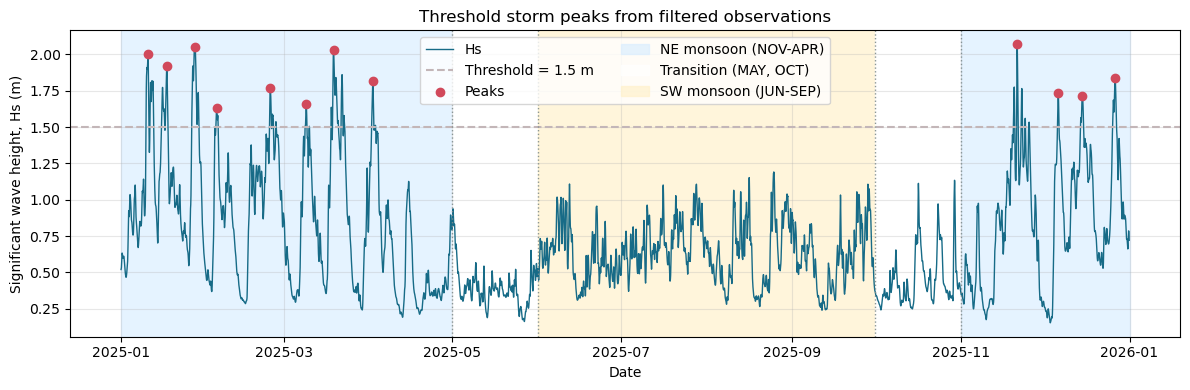

In [ ]:
peak_detection_hs = observations['Hs_m'].to_numpy()
peak_indices, peak_properties = find_peaks(
    np.nan_to_num(peak_detection_hs, nan=-np.inf),
    height=threshold_m,
    distance=max(1, int(np.ceil(minimum_peak_distance_hours / time_step_hours)))
)

peaks = observations.iloc[peak_indices].copy()
excesses = peaks['Hs_m'] - threshold_m
storm_peaks = peaks[['Hs_m', 'Tp_s', 'Wave_direction_deg']].copy()
storm_peaks.insert(0, 'Peak date', storm_peaks.index)
storm_peaks.insert(1, 'Excess above threshold (m)', excesses.to_numpy())
storm_peaks = storm_peaks.rename(columns={
    'Hs_m': 'Hs (m)',
    'Tp_s': 'Tp (s)',
    'Wave_direction_deg': 'Wave direction (deg)'
}).reset_index(drop=True)

print(f'Independent peaks above {threshold_m:.1f} m: {len(storm_peaks)}')
print('Peak detection and reported storm values both use the six-hour filtered observations.')
if SAVE:
    storm_peaks.to_csv(result_dir / 'longterm_threshold_peaks_2025.csv', index=False)
display(storm_peaks.round(3))

fig, axis = plt.subplots(figsize=(12, 4))
axis.plot(observations.index, observations['Hs_m'], linewidth=1.0, color='#176b87', label='Hs')
axis.axhline(threshold_m, color="#c3b6b8", linestyle='--', label=f'Threshold = {threshold_m:.1f} m')
if not storm_peaks.empty:
    axis.scatter(storm_peaks['Peak date'], storm_peaks['Hs (m)'], color='#d1495b', zorder=3, label='Peaks')

analysis_year = observations.index.min().year
seasonal_periods = [
    ('NE monsoon (NOV-APR)', pd.Timestamp(analysis_year, 1, 1), pd.Timestamp(analysis_year, 5, 1), '#dbeeff'),
    ('Transition (MAY, OCT)', pd.Timestamp(analysis_year, 5, 1), pd.Timestamp(analysis_year, 6, 1), "#ffffff"),
    ('SW monsoon (JUN-SEP)', pd.Timestamp(analysis_year, 6, 1), pd.Timestamp(analysis_year, 10, 1), '#fff2cc'),
    ('Transition (MAY, OCT)', pd.Timestamp(analysis_year, 10, 1), pd.Timestamp(analysis_year, 11, 1), '#ffffff'),
    ('NE monsoon (NOV-APR)', pd.Timestamp(analysis_year, 11, 1), pd.Timestamp(analysis_year + 1, 1, 1), '#dbeeff')
]
shown_labels = set()
for label, start, end, color in seasonal_periods:
    legend_label = label if label not in shown_labels else '_nolegend_'
    axis.axvspan(start, end, color=color, alpha=0.7, label=legend_label)
    shown_labels.add(label)

monsoon_boundaries = [
    pd.Timestamp(analysis_year, 5, 1),
    pd.Timestamp(analysis_year, 6, 1),
    pd.Timestamp(analysis_year, 10, 1),
    pd.Timestamp(analysis_year, 11, 1)
]
for boundary in monsoon_boundaries:
    axis.axvline(boundary, color='#7f8c8d', linestyle=':', linewidth=1.0, alpha=0.9)

axis.set_ylabel('Significant wave height, Hs (m)')
axis.set_xlabel('Date')
axis.set_title('Threshold storm peaks from filtered observations')
axis.grid(alpha=0.3)
axis.legend(loc='upper center', fontsize=10, ncol=2)
fig.tight_layout()
if SAVE:
    fig.savefig(result_dir / 'longterm_threshold_peaks_2025.png', dpi=300, bbox_inches='tight')
plt.show()

# 8. Delft3D input summary

In [ ]:
seasonal_rows = []
for season in ('NE Monsoon', 'SW Monsoon', 'Transition'):
    values = longterm_summary.loc[season]
    seasonal_rows.append({
        'Scenario': season,
        'Hs mean (m)': values['Mean Hs (m)'],
        'Hs 95th percentile (m)': values['95th percentile Hs (m)'],
        'Tp mean (s)': values['Mean Tp (s)'],
        'Tm0 mean (s)': values['Mean Tm0 (s)'],
        'Wave direction (deg)': values['Mean wave direction (deg)'],
        'u10 mean (m/s)': values['Mean u10 (m/s)'],
        'v10 mean (m/s)': values['Mean v10 (m/s)'],
        'Wind speed mean (m/s)': values['Mean wind speed (m/s)']
    })

seasonal_delft3d_conditions = pd.DataFrame(seasonal_rows).set_index('Scenario')
print('Delft3D seasonal conditions calculated from ERA5')
if SAVE:
    seasonal_delft3d_conditions.to_csv(result_dir / 'longterm_delft3d_seasonal_conditions.csv')
display(seasonal_delft3d_conditions.round(3))

# Derive the duration of the strongest threshold event from consecutive hourly exceedances.
exceedance_mask = observations['Hs_m'] >= threshold_m
exceedance_groups = exceedance_mask.ne(exceedance_mask.shift()).cumsum()
exceedance_events = observations[exceedance_mask].groupby(exceedance_groups[exceedance_mask]).agg(
    Start=('Hs_m', lambda values: values.index.min()),
    End=('Hs_m', lambda values: values.index.max()),
    Duration_hours=('Hs_m', lambda values: len(values) * time_step_hours),
    Maximum_Hs_m=('Hs_m', 'max')
)

if storm_peaks.empty:
    storm_delft3d_conditions = pd.DataFrame()
    print('No threshold storm event is available for a storm-condition input.')
else:
    strongest_peak = storm_peaks.loc[storm_peaks['Hs (m)'].idxmax()]
    strongest_peak_time = pd.Timestamp(strongest_peak['Peak date'])
    strongest_group = exceedance_groups.loc[strongest_peak_time]
    strongest_event = exceedance_events.loc[strongest_group]
    storm_delft3d_conditions = pd.DataFrame([{
        'Condition': 'Strongest threshold event',
        'Peak date': strongest_peak_time,
        'Duration (h)': strongest_event['Duration_hours'],
        'Hs (m)': strongest_peak['Hs (m)'],
        'Tp (s)': strongest_peak['Tp (s)'],
        'Tm0 (s)': observations.loc[strongest_peak_time, 'Tm0_s'],
        'Wave direction (deg)': strongest_peak['Wave direction (deg)'],
        'Start': strongest_event['Start'],
        'End': strongest_event['End']
    }]).set_index('Condition')
    print('Delft3D storm condition calculated from the strongest threshold event')
    if SAVE:
        storm_delft3d_conditions.to_csv(result_dir / 'longterm_delft3d_storm_condition.csv')
    display(storm_delft3d_conditions.round(3))

Delft3D seasonal conditions calculated from ERA5


,Hs mean (m),Hs 95th percentile (m),Tp mean (s),Tm0 mean (s),Wave direction (deg),u10 mean (m/s),v10 mean (m/s),Wind speed mean (m/s)
Scenario,,,,,,,,
NE Monsoon,0.904,1.710,5.691,4.701,81.790,-5.541,-1.122,6.385
SW Monsoon,0.637,0.983,4.185,3.569,227.722,5.477,2.219,6.277
Transition,0.536,1.284,4.887,3.963,139.941,-0.177,-0.030,4.542


Delft3D storm condition calculated from the strongest threshold event


,Peak date,Duration (h),Hs (m),Tp (s),Tm0 (s),Wave direction (deg),Start,End
Condition,,,,,,,,
Strongest threshold event,2025-11-21 08:00:00,14.0,2.07,6.88,5.812,63.2,2025-11-21 04:00:00,2025-11-21 17:00:00


In [ ]:
# Percentage of swell waves (Hs > 1 m and Tp > 10 s) from the loaded ERA5 fields
swell_hs_m = 1.0
swell_tp_s = 10.0

swell_data = pd.DataFrame({
    'Hs_m': point_series(hs),
    'Tp_s': point_series(tp)
}).dropna()

is_swell = (swell_data['Hs_m'] > swell_hs_m) & (swell_data['Tp_s'] > swell_tp_s)

swell_rows = [{'Period': 'Annual', 'Swell (%)': 100 * is_swell.mean()}]
for season, months in season_months.items():
    in_season = swell_data.index.month.isin(months)
    swell_rows.append({'Period': season, 'Swell (%)': 100 * is_swell[in_season].mean()})

swell_summary = pd.DataFrame(swell_rows).set_index('Period')
if SAVE:
    swell_summary.to_csv(result_dir / 'longterm_swell_percentage.csv')
display(swell_summary.round(2))

annual_swell = swell_summary.loc['Annual', 'Swell (%)']
print(f'Littoral input, swell percentage: {min(annual_swell, 40):.1f} % (allowed range 0-40 %)')


,Swell (%)
Period,
Annual,0.39
NE Monsoon,0.86
SW Monsoon,0.00
Transition,0.14


Littoral input, swell percentage: 0.4 % (allowed range 0-40 %)


# Assumptions and limitations

- The analysis uses one year of ERA5 data from 2025. These results describe the selected year and should not be treated as a long-term climatology or a return-period analysis.

- Wave direction is filtered using circular averaging. Directly averaging degree values would be incorrect near the 0/360-degree boundary.

- The NE Monsoon is defined as November to April, the SW Monsoon as June to September, and the transition period as May and October. These are analysis choices.

- `u10`, `v10`, and derived wind speed are ERA5 model estimates. They are reported as filtered long-term context but are not used as storm-design wind observations because the historical comparison showed that ERA5 can underestimate extreme winds.

- No directional-spreading values are imposed or reported. Directional spreading must be supplied separately from a documented model choice or observations.

- The Delft3D tables are statistical summaries of filtered ERA5 conditions. They are not calibrated boundary conditions, validated design storms, or return-period conditions.